### What Are Embeddings?
Embeddings as a way to translate words into a language that computers understand - numbers (01010101) :)

In [16]:
import numpy as np
import matplotlib.pyplot as plt

In [17]:
# Simplified 2D example (real embeddings have hundreds of dimensions)
word_embeddings = {
    "cat": [0.8, 0.6],
    "kitten": [0.75, 0.65],
    "dog": [0.7, 0.3],
    "puppy": [0.65, 0.35],
    "car": [-0.5, 0.2],
    "truck": [-0.45, 0.15],
    "Bike":[-0.5,0.68],
    "cycle":[-0.6,0.7],
    "man":[0.5,0.18],
    "woman":[-0.4,-0.16]
}

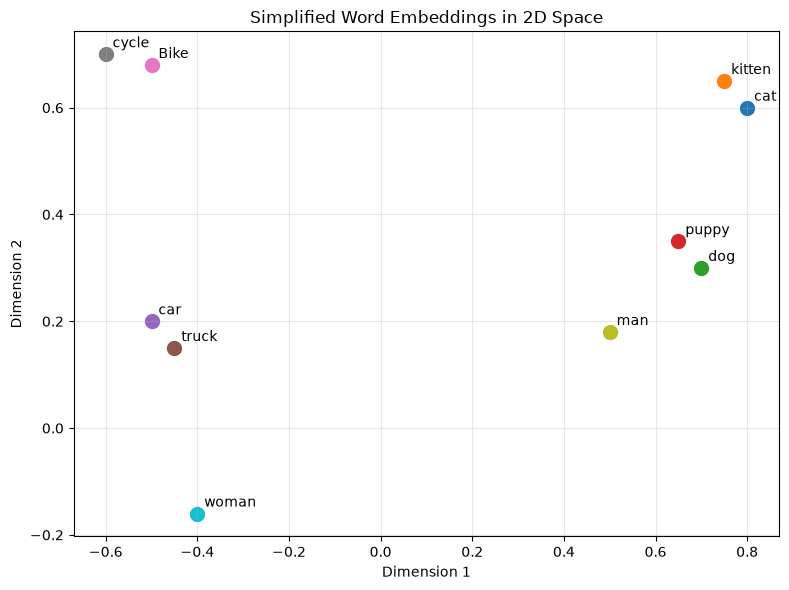

In [18]:
fig, ax = plt.subplots(figsize=(8, 6))

for word, coords in word_embeddings.items():
    ax.scatter(coords[0], coords[1], s=100)
    ax.annotate(word, (coords[0], coords[1]), xytext=(5, 5), 
                textcoords='offset points')

ax.set_xlabel('Dimension 1')
ax.set_ylabel('Dimension 2')
ax.set_title('Simplified Word Embeddings in 2D Space')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Measuring SImilarity using Cosine Similarity

In [19]:
def cosine_similarity(vec1, vec2):
    """
    Cosine similarity measures the angle between two vectors.
    - Result close to 1: Very similar
    - Result close to 0: Not related
    - Result close to -1: Opposite meanings
    """

    dot_product=np.dot(vec1,vec2)
    norm_a=np.linalg.norm(vec1)
    norm_b=np.linalg.norm(vec2)
    return dot_product/(norm_a * norm_b)

In [20]:
# Example
car_vector = [0.8, 0.6, 0.3]
jeep_vector = [0.75, 0.65, 0.35]
hooman = [-0.5, 0.2, 0.1]

car_jeepsim =cosine_similarity(car_vector,jeep_vector)
print(f'car and jeep similarity:',car_jeepsim)
jeep_hoomasim =cosine_similarity(car_vector,hooman)
print(f'Jeep and Human sim:',jeep_hoomasim)

car and jeep similarity: 0.9966186334192183
Jeep and Human sim: -0.4371858854891681


# Creating Embeddings using Hugging face model(Sentence Transformer Models)

In [22]:
### Huggingface And OpenAI Models

from langchain_huggingface import HuggingFaceEmbeddings

## Initialize a simple Embedding model(no API Key needed!)
embeddings=HuggingFaceEmbeddings(
    model_name="sentence-transformers/all-MiniLM-L6-v2"
)
embeddings

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 1558.66it/s]


HuggingFaceEmbeddings(model_name='sentence-transformers/all-MiniLM-L6-v2', cache_folder=None, model_kwargs={}, encode_kwargs={}, query_encode_kwargs={}, multi_process=False, show_progress=False)

In [23]:
text="Hello, we are learning about embeddings!"

embedding=embeddings.embed_query(text)
print(f"Text: {text}")
print(f"Embedding length : {len(embedding)}")
print(embedding)

Text: Hello, we are learning about embeddings!
Embedding length : 384
[-0.025066478177905083, -0.09507961571216583, 0.03305555135011673, -1.6037953173508868e-05, 0.02836175262928009, 0.06324303150177002, 0.0018598594469949603, -0.019567232578992844, 0.026456333696842194, -0.019211530685424805, 0.0022862637415528297, 0.06288160383701324, 0.04927307739853859, 0.03898654878139496, -0.059401463717222214, 0.013151459395885468, 0.04013670235872269, 0.07015501707792282, -0.06948458403348923, 0.028694158419966698, -0.028100956231355667, -0.04122215881943703, 0.05044810473918915, -0.07856075465679169, 0.02466711774468422, -0.011472421698272228, -0.048036813735961914, 0.036424461752176285, 0.08534103631973267, -0.0789780467748642, 0.050823457539081573, 0.005546345841139555, -0.03475702181458473, 0.07133201509714127, -0.03236962482333183, 0.08793317526578903, 0.0374387763440609, -0.0028121285140514374, -0.04144476354122162, -0.0037708531599491835, 0.020348969846963882, 0.0460243821144104, -0.0426

In [25]:
sentences = [
    "The cat sat on the mat",
    "The cat sat on the mat",
    "The dog played in the yard",
    "I love programming in Python",
    "Python is my favorite programming language"
]

embedding_sentence=embeddings.embed_documents(sentences)

print(embedding_sentence[0])
print(embedding_sentence[4])

[0.1304018497467041, -0.011870148591697216, -0.02811707742512226, 0.05123859643936157, -0.05597455054521561, 0.030191544443368912, 0.030161334201693535, 0.024698354303836823, -0.018370533362030983, 0.05876684561371803, -0.024953192099928856, 0.06015422195196152, 0.039831701666116714, 0.03323056921362877, -0.06131143122911453, -0.049373093992471695, -0.05486350879073143, -0.040076106786727905, 0.05642911046743393, 0.03915660083293915, -0.034737054258584976, -0.013247678987681866, 0.03196614608168602, -0.06349923461675644, -0.06017854064702988, 0.07823454588651657, -0.028303848579525948, -0.04744282737374306, 0.04035931080579758, -0.0066308933310210705, -0.06674092262983322, -0.004191305488348007, -0.025311704725027084, 0.05334162339568138, 0.017428148537874222, -0.09792355448007584, 0.006061299704015255, -0.06524168699979782, 0.04557259380817413, 0.023641807958483696, 0.07658479362726212, -0.010264316573739052, -0.004076763521879911, -0.06232282891869545, 0.03370523452758789, 0.01866111

In [40]:
for i in range(len(sentences)):
    for j in range(i+1,len(sentences)):
        similarity=cosine_similarity(embedding_sentence[i],embedding_sentence[j])

        print(f"'{sentences[i]}' vs '{sentences[j]}'")
        print(f"Similarity: {similarity:.3f}\n")

'The cat sat on the mat' vs 'The cat sat on the mat'
Similarity: 1.000

'The cat sat on the mat' vs 'The dog played in the yard'
Similarity: 0.188

'The cat sat on the mat' vs 'I love programming in Python'
Similarity: 0.020

'The cat sat on the mat' vs 'Python is my favorite programming language'
Similarity: 0.003

'The cat sat on the mat' vs 'The dog played in the yard'
Similarity: 0.188

'The cat sat on the mat' vs 'I love programming in Python'
Similarity: 0.020

'The cat sat on the mat' vs 'Python is my favorite programming language'
Similarity: 0.003

'The dog played in the yard' vs 'I love programming in Python'
Similarity: 0.122

'The dog played in the yard' vs 'Python is my favorite programming language'
Similarity: 0.098

'I love programming in Python' vs 'Python is my favorite programming language'
Similarity: 0.877



# Lets create a small/semantic based search rag lol!

In [41]:
from langchain_huggingface import HuggingFaceEmbeddings


def simple_Rag(userq,groundingdata,top_k=3):
    embedding_model =HuggingFaceEmbeddings(
        model_name="sentence-transformers/all-MiniLM-L6-v2"
    )
    quet_emd = embedding_model.embed_query(userq)
    data_emd = embedding_model.embed_documents(groundingdata)

    similarities = []
    for i,doc_emb in enumerate(data_emd):
        similarity = cosine_similarity(quet_emd,doc_emb)
        similarities.append((similarity,sample_Grounding_data[i]))
    similarities.sort(reverse=True)
    return similarities[:top_k]

def cosine_similarity(vec1, vec2):
    """   Cosine similarity measures the angle between two vectors.
    - Result close to 1: Very similar
    - Result close to 0: Not related
    - Result close to -1: Opposite meanings
    """

    dot_product=np.dot(vec1,vec2)
    norm_a=np.linalg.norm(vec1)
    norm_b=np.linalg.norm(vec2)
    return dot_product/(norm_a * norm_b)
    

sample_Grounding_data = [
    "Langchain is an AI api and also agent orchestration tool",
    "Bahubali is a good movie",
    "Loki gonna save us in Doom's day?",
    "Langchain has changed the AI based solution building rapidly boom!!",
    "Bahubali was released in 2015.",
    "Is Dr Von doom really good in another univers?",
    "In the world of GEN AI and stuff, Langchain is playing a major role."
]

In [42]:
user_query = "Bahubali movie"
results=simple_Rag(user_query,sample_Grounding_data)
results

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 2911.06it/s]


[(np.float64(0.8607312065290457), 'Bahubali is a good movie'),
 (np.float64(0.764054521783859), 'Bahubali was released in 2015.'),
 (np.float64(0.19972506312582475),
  'Langchain is an AI api and also agent orchestration tool')]

In [43]:
print(f"\n🔎 Semantic Search Results for: '{user_query}'")
for score, doc in results:
    print(f"Score: {score:.3f} | {doc}")


🔎 Semantic Search Results for: 'Bahubali movie'
Score: 0.861 | Bahubali is a good movie
Score: 0.764 | Bahubali was released in 2015.
Score: 0.200 | Langchain is an AI api and also agent orchestration tool


In [46]:
# Popular models comparison free models
models = {
    "all-MiniLM-L6-v2": {
        "size": 384,
        "description": "Fast and efficient, good quality",
        "use_case": "General purpose, real-time applications"
    },
    "all-mpnet-base-v2": {
        "size": 768,
        "description": "Best quality, slower than MiniLM",
        "use_case": "When quality matters more than speed"
    },
    "all-MiniLM-L12-v2": {
        "size": 384,
        "description": "Slightly better than L6, bit slower",
        "use_case": "Good balance of speed and quality"
    },
    "multi-qa-MiniLM-L6-cos-v1": {
        "size": 384,
        "description": "Optimized for question-answering",
        "use_case": "Q&A systems, semantic search"
    },
    "paraphrase-multilingual-MiniLM-L12-v2": {
        "size": 384,
        "description": "Supports 50+ languages",
        "use_case": "Multilingual applications"
    }
}

print("📊 Popular Open Source Embedding Models:\n")
for model_name, info in models.items():
    print(f"Model: sentence-transformers/{model_name}")
    print(f"  📏 Embedding size: {info['size']} dimensions")
    print(f"  📝 Description: {info['description']}")
    print(f"  🎯 Use case: {info['use_case']}\n")


📊 Popular Open Source Embedding Models:

Model: sentence-transformers/all-MiniLM-L6-v2
  📏 Embedding size: 384 dimensions
  📝 Description: Fast and efficient, good quality
  🎯 Use case: General purpose, real-time applications

Model: sentence-transformers/all-mpnet-base-v2
  📏 Embedding size: 768 dimensions
  📝 Description: Best quality, slower than MiniLM
  🎯 Use case: When quality matters more than speed

Model: sentence-transformers/all-MiniLM-L12-v2
  📏 Embedding size: 384 dimensions
  📝 Description: Slightly better than L6, bit slower
  🎯 Use case: Good balance of speed and quality

Model: sentence-transformers/multi-qa-MiniLM-L6-cos-v1
  📏 Embedding size: 384 dimensions
  📝 Description: Optimized for question-answering
  🎯 Use case: Q&A systems, semantic search

Model: sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2
  📏 Embedding size: 384 dimensions
  📝 Description: Supports 50+ languages
  🎯 Use case: Multilingual applications

